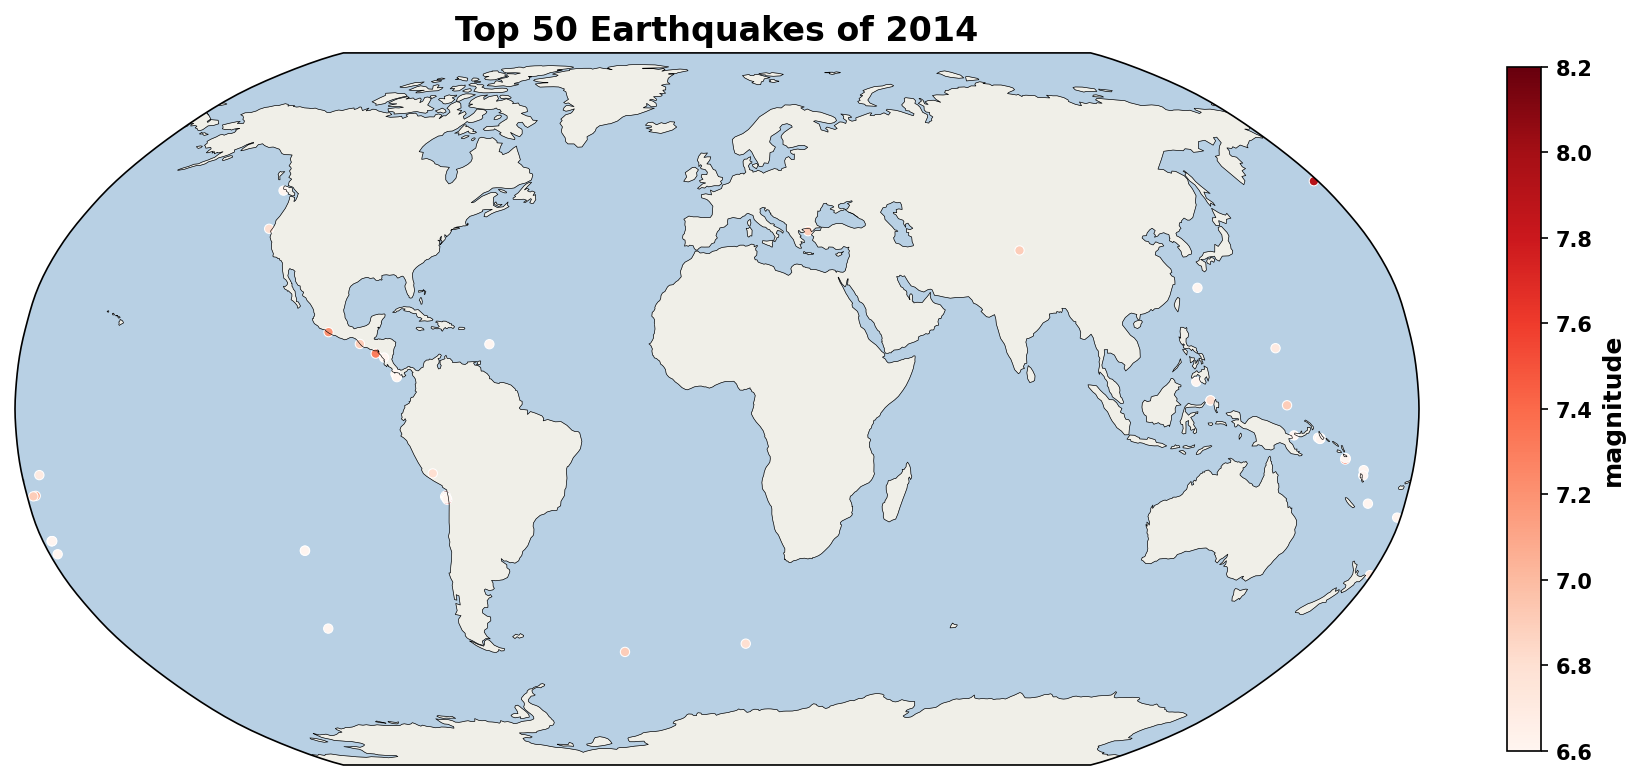

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
from cartopy.io import DownloadWarning
warnings.filterwarnings("ignore", category=DownloadWarning)

df = pd.read_csv("usgs_earthquakes.csv")
df["time"] = pd.to_datetime(df["time"])
df_2014 = df[df["time"].dt.year == 2014]
top50 = df_2014.nlargest(50, "mag")
fig = plt.figure(figsize=(12,6), dpi=150)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="#f0efe8", edgecolor="gray", lw=0.3)
ax.add_feature(cfeature.OCEAN, facecolor="#b8d0e4")
ax.coastlines(lw=0.3)
scatter = ax.scatter(
    top50["longitude"],
    top50["latitude"],
    c=top50["mag"],
    vmin=6.6,
    vmax=8.2,
    cmap="Reds",
    s=20,
    edgecolor="white",
    linewidth=0.5,
    transform=ccrs.PlateCarree()
)
ax.set_title("Top 50 Earthquakes of 2014", fontsize=16, weight="bold")
cbar = plt.colorbar(scatter, ax=ax, shrink=0.8)
cbar.set_label("magnitude", fontsize=12)
plt.tight_layout()
plt.savefig("earthquake_2014_top50.png", dpi=300, bbox_inches="tight")
plt.show()

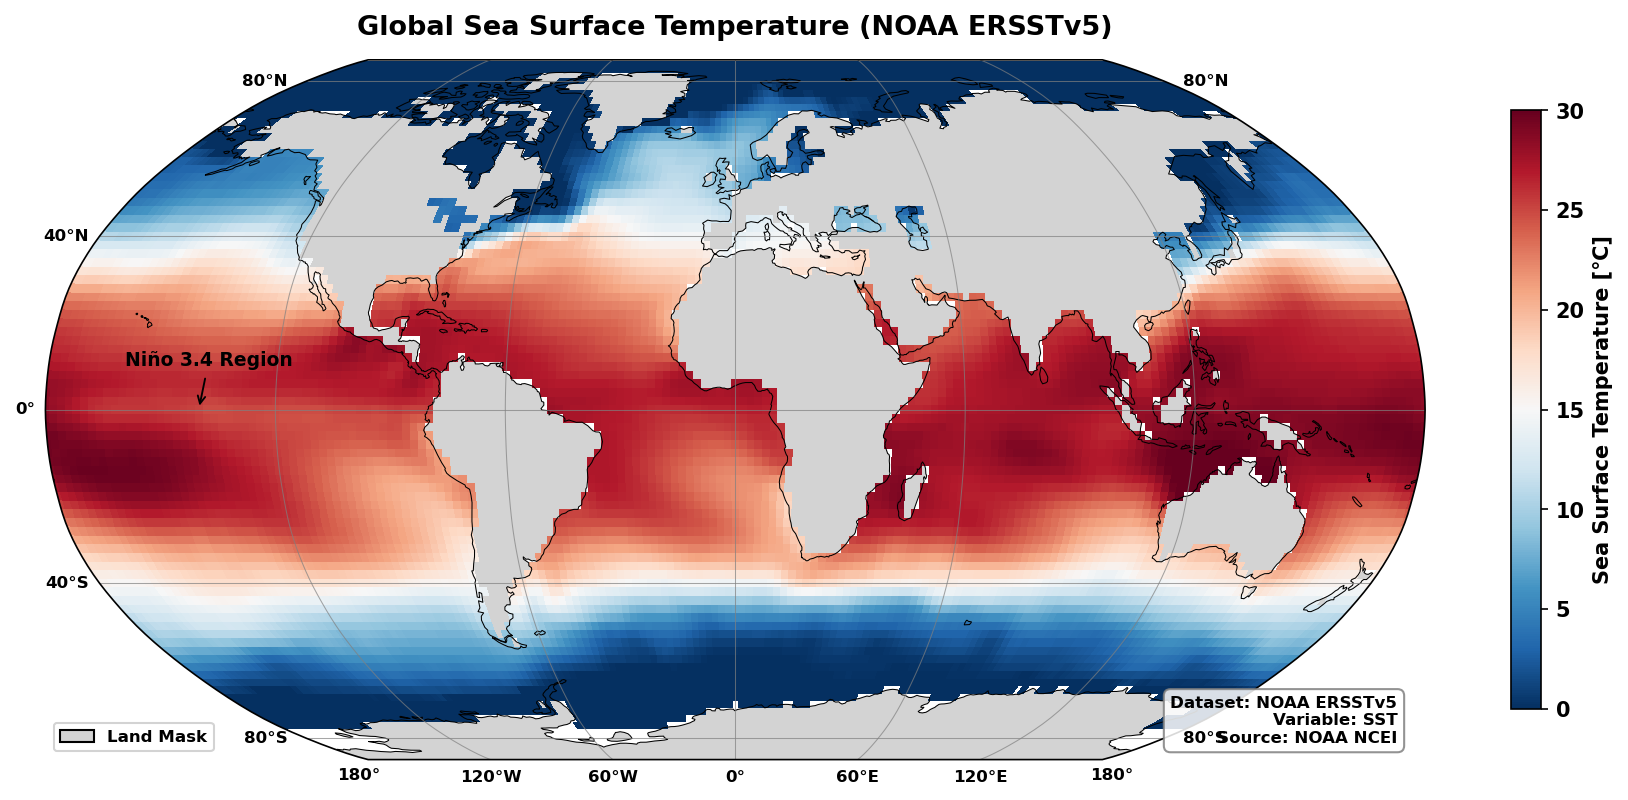

In [16]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Patch
ds = xr.open_dataset("sst.mnmean.nc")
sst_data = ds["sst"].isel(time=0)
fig = plt.figure(figsize=(12,6), dpi=150)
ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson())
ax.set_global()
pcm = sst_data.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=0, vmax=30,
    add_colorbar=False
)
gl = ax.gridlines(draw_labels=True, lw=0.5, color="gray", alpha=0.7)
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.xlabel_style = {"size":8}
gl.ylabel_style = {"size":8}
gl.xlocator = plt.MaxNLocator(6)
gl.ylocator = plt.MaxNLocator(5)
ax.set_xlabel("Longitude", fontsize=11, labelpad=12)
ax.set_ylabel("Latitude", fontsize=11, labelpad=12)
ax.set_title("Global Sea Surface Temperature (NOAA ERSSTv5)", fontsize=13, pad=12)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
ax.add_feature(cfeature.COASTLINE, lw=0.5)
cbar = fig.colorbar(pcm, ax=ax, shrink=0.7)
cbar.set_label("Sea Surface Temperature [℃]", fontsize=10)
legend_ele = [Patch(facecolor="lightgray", edgecolor="black", label="Land Mask")]
ax.legend(handles=legend_ele, loc="lower left", fontsize=8, framealpha=0.85)
ax.annotate("Niño 3.4 Region", xy=(-140, 0), xytext=(-160, 10),
            arrowprops=dict(arrowstyle="->", lw=0.9, color="black"),
            transform=ccrs.PlateCarree(), fontsize=9)
text_info = "Dataset: NOAA ERSSTv5\nVariable: SST\nSource: NOAA NCEI"
box_props = dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85, edgecolor="gray")
ax.text(0.98, 0.02, text_info, transform=ax.transAxes, fontsize=8,
        va="bottom", ha="right", bbox=box_props)

plt.tight_layout()
plt.savefig("2_1_global_sst.png", dpi=300, bbox_inches="tight")
plt.show()

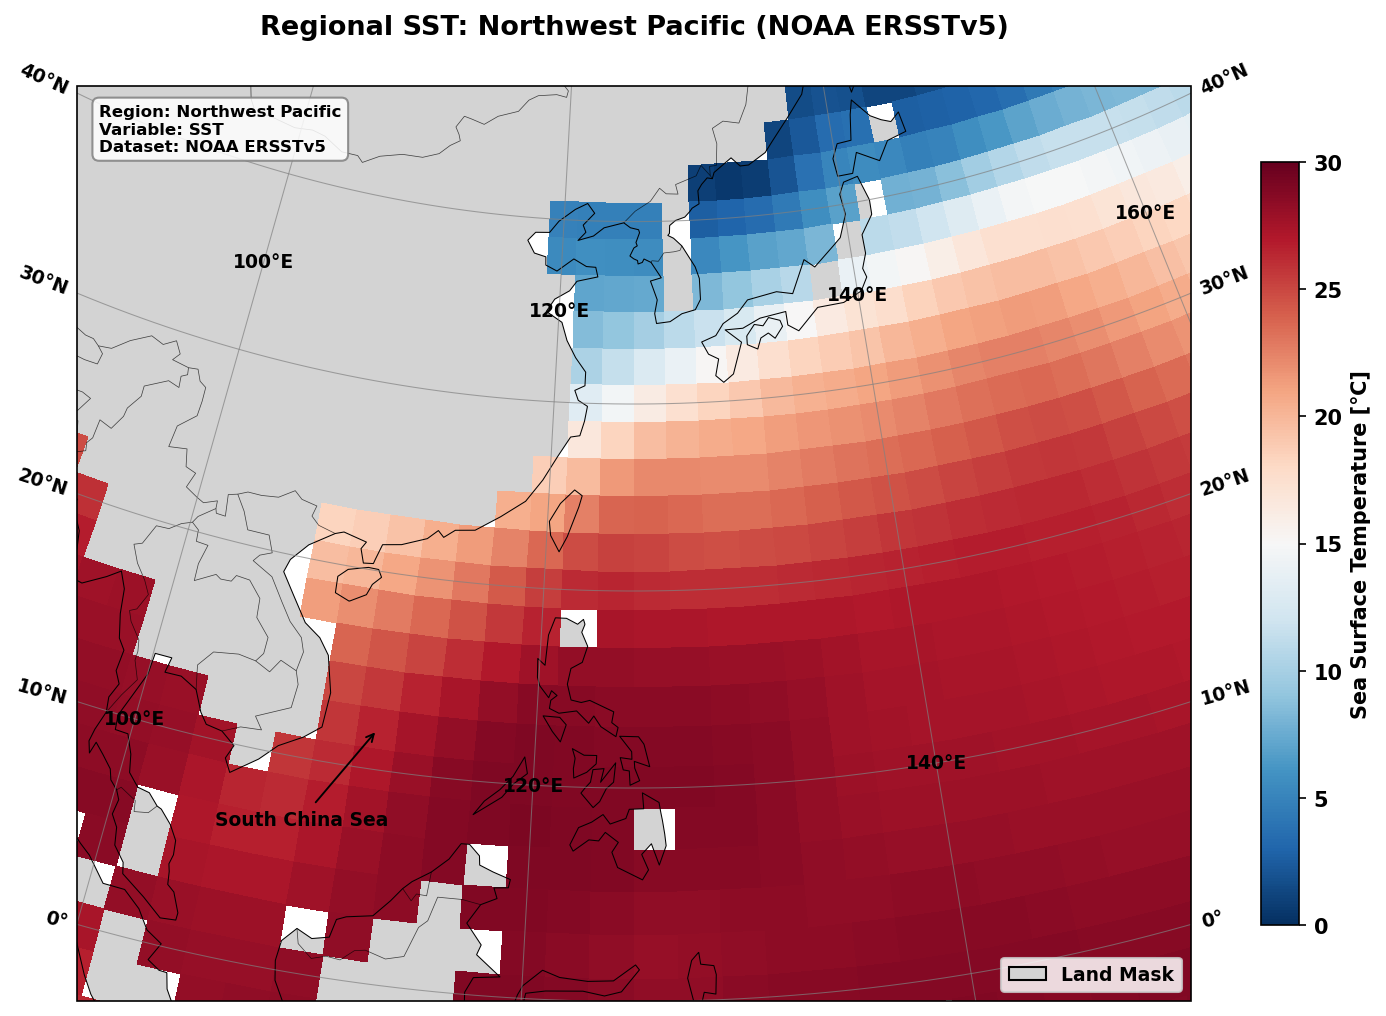

In [19]:
ds = xr.open_dataset("sst.mnmean.nc")
sst_data = ds["sst"].isel(time=0)
fig = plt.figure(figsize=(10,7), dpi=150)
proj = ccrs.LambertConformal(central_longitude=125, central_latitude=20)
ax = fig.add_subplot(1,1,1, projection=proj)
ax.set_extent([100, 150, 0, 45], crs=ccrs.PlateCarree())
pcm = sst_data.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=0, vmax=30,
    add_colorbar=False
)
gl = ax.gridlines(draw_labels=True, lw=0.5, color="gray", alpha=0.7)
gl.xlabel_style = {"size":9}
gl.ylabel_style = {"size":9}
ax.set_xlabel("Longitude", fontsize=11, labelpad=12)
ax.set_ylabel("Latitude", fontsize=11, labelpad=12)
ax.set_title("Regional SST: Northwest Pacific (NOAA ERSSTv5)", fontsize=13, pad=12)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
ax.add_feature(cfeature.COASTLINE, lw=0.5)
ax.add_feature(cfeature.BORDERS, lw=0.35, alpha=0.7)
cbar = fig.colorbar(pcm, ax=ax, shrink=0.8)
cbar.set_label("Sea Surface Temperature [℃]", fontsize=10)
legend_ele = [Patch(facecolor="lightgray", edgecolor="black", label="Land Mask")]
ax.legend(handles=legend_ele, loc="lower right", fontsize=9, framealpha=0.85)
text_info = "Region: Northwest Pacific\nVariable: SST\nDataset: NOAA ERSSTv5"
box_props = dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85, edgecolor="gray")
ax.text(0.02, 0.98, text_info, transform=ax.transAxes, fontsize=8,
        va="top", ha="left", bbox=box_props)
ax.annotate("South China Sea", xy=(112,12), xytext=(105,6),
            arrowprops=dict(arrowstyle="->", lw=0.9, color="black"),
            transform=ccrs.PlateCarree(), fontsize=9)

plt.tight_layout()
plt.savefig("2_2_regional_sst.png", dpi=300, bbox_inches="tight")
plt.show()